In [1]:
%pip install numpy matplotlib

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 23.2.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import numpy as np
import matplotlib.pyplot as plt
from collections import Counter

In [3]:
dataset = np.loadtxt("knn_dataset_exercicio_1.txt", delimiter='|', skiprows=2, usecols={1, 2, 3})

X_train = dataset[:, :2]

y_train = dataset[:, 2].astype(int)

print("Amostra das características (X_train):")
print(X_train[:5])
print("\nAmostra dos rótulos (y_train):")
print(y_train[:5])
print("\nDataset Completo")
print(dataset.astype(int))

Amostra das características (X_train):
[[2000.  500.]
 [2500.  700.]
 [3000.  800.]
 [3200. 1000.]
 [3500. 1200.]]

Amostra dos rótulos (y_train):
[1 1 1 2 2]

Dataset Completo
[[2000  500    1]
 [2500  700    1]
 [3000  800    1]
 [3200 1000    2]
 [3500 1200    2]
 [4000 1500    2]
 [4500 1600    2]
 [4800 1700    2]
 [5000 2000    2]
 [5500 2100    2]
 [6000 2500    3]
 [6200 2700    3]
 [6500 3000    3]
 [7000 3200    3]
 [7200 3400    3]
 [7500 3600    3]
 [8000 4000    3]
 [8200 4200    3]
 [8500 4500    3]
 [9000 4800    3]]


In [4]:
def calcular_distancia_euclidiana(ponto1, ponto2):
    """Calcula a distância euclidiana entre dois pontos."""
    return np.sqrt(np.sum((ponto1 - ponto2)**2))

def encontrar_vizinhos(X_train, y_train, ponto_teste, k):
    """Encontra os k vizinhos mais próximos de um ponto de teste."""
    distancias = []
    for i, ponto_treino in enumerate(X_train):
        dist = calcular_distancia_euclidiana(ponto_treino, ponto_teste)
        distancias.append((dist, y_train[i]))
    
    # Ordena a lista de distâncias em ordem crescente
    distancias.sort(key=lambda x: x[0])
    
    # Retorna os k vizinhos mais próximos (seus rótulos)
    vizinhos = [distancia[1] for distancia in distancias[:k]]
    return vizinhos

def prever_classificacao(vizinhos):
    """Faz a previsão com base no voto majoritário dos vizinhos."""
    # Conta a ocorrência de cada classe nos vizinhos
    contagem_votos = Counter(vizinhos)
    # Retorna a classe mais comum
    previsao = contagem_votos.most_common(1)[0][0]
    return previsao

In [7]:
# Ponto que queremos classificar
novo_tumor = np.array([3000, 500])
k = 5

# Encontra os vizinhos e faz a previsão
vizinhos_proximos = encontrar_vizinhos(X_train, y_train, novo_tumor, k)
previsao_final = prever_classificacao(vizinhos_proximos)

# Mapeia o resultado para um texto explicativo
resultado_texto = "Benigno" if previsao_final == 0 else "Maligno"

print(f"O novo tumor tem as características: {novo_tumor}")
print(f"O valor de 'k' escolhido foi: {k}")
print(f"As classes dos vizinhos mais próximos são: {vizinhos_proximos}")
print("-" * 50)
print(f"--> Previsão Final: O novo tumor é classificado como {resultado_texto} (Classe {previsao_final})")

O novo tumor tem as características: [3000  500]
O valor de 'k' escolhido foi: 5
As classes dos vizinhos mais próximos são: [np.int64(1), np.int64(1), np.int64(2), np.int64(2), np.int64(1)]
--------------------------------------------------
--> Previsão Final: O novo tumor é classificado como Maligno (Classe 1)


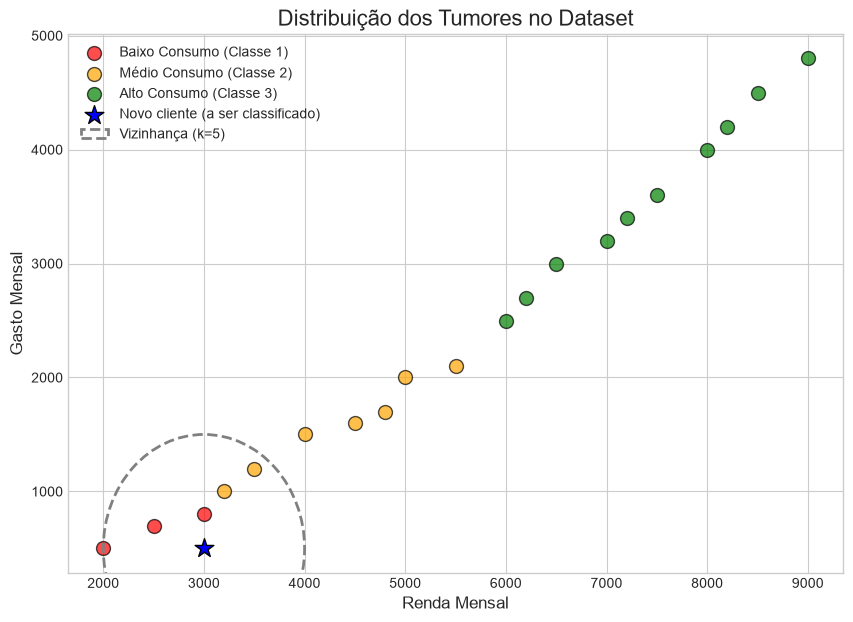

In [9]:
plt.style.use('seaborn-v0_8-whitegrid')
fig, ax = plt.subplots(figsize=(10, 7))

ax.scatter(X_train[y_train == 1, 0], X_train[y_train == 1, 1],
           c='red', s=100, edgecolor='k', alpha=0.7, label='Baixo Consumo (Classe 1)')

ax.scatter(X_train[y_train == 2, 0], X_train[y_train == 2, 1],
           c='orange', s=100, edgecolor='k', alpha=0.7, label='Médio Consumo (Classe 2)')

ax.scatter(X_train[y_train == 3, 0], X_train[y_train == 3, 1],
           c='green', s=100, edgecolor='k', alpha=0.7, label='Alto Consumo (Classe 3)')

# Plotando o novo ponto de dados a ser classificado
ax.scatter(novo_tumor[0], novo_tumor[1], c='blue', s=200,
           edgecolor='k', marker='*', label='Novo cliente (a ser classificado)')

# Destaque para os vizinhos mais próximos
indices_vizinhos = np.argsort([calcular_distancia_euclidiana(p, novo_tumor) for p in X_train])[:k]
pontos_vizinhos = X_train[indices_vizinhos]

# Desenhando um círculo que engloba os vizinhos
distancia_maxima = calcular_distancia_euclidiana(novo_tumor, pontos_vizinhos[-1])
circulo = plt.Circle(novo_tumor, distancia_maxima, color='gray', fill=False,
                     linestyle='--', linewidth=2, label=f'Vizinhança (k={k})')
ax.add_artist(circulo)

ax.set_title('Distribuição dos Tumores no Dataset', fontsize=16)
ax.set_ylabel('Gasto Mensal', fontsize=12)
ax.set_xlabel('Renda Mensal', fontsize=12)
ax.legend()
plt.show()